# Black Friday: чистая и последовательная версия решения

Этот ноутбук пересобирает решение с нуля на основе всех версий `black_friday_solution*.ipynb`.

Что исправлено относительно исходной эволюции:
- устранены дублирующиеся EDA-блоки и повторные построения одних и тех же графиков;
- убрано смешение этапов: сначала данные и гипотезы, затем признаки, затем обучение, затем интерпретация;
- исключены несогласованные ручные списки признаков, которые не совпадали с реально построенными столбцами;
- удалены ссылки на отсутствующие переменные вроде `ada_oof` и `ada_pred`;
- все финальные результаты, графики и prediction-file строятся из одного воспроизводимого пайплайна.

## Ключевые итоги
- Baseline RMSE: `2892.49`
- Финальный RMSE: `2469.91`
- Итоговое число признаков: `27`
- Веса ансамбля: `{'LightGBM': 0.75, 'XGBoost': 0.25}`

**Публичная версия:** пути настроены относительно репозитория. Сохранённые результаты относятся к исходному запуску; ограничения CV описаны в README. Полный повторный запуск при публикации не выполнялся.

## 1. Импорты и конфигурация

Ниже подключается единый модуль `black_friday_pipeline.py`, в котором собраны функции для:
- чтения данных;
- построения признаков и OOF target encoding;
- статистического ранжирования;
- обучения baseline и продвинутых моделей;
- ансамблирования;
- генерации графиков и export-файлов.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import Image, display, Markdown

import os
WORKSPACE = Path.cwd()
if not (WORKSPACE / 'black_friday_pipeline.py').is_file():
    raise FileNotFoundError('Open this notebook from the cloned repository root.')
sys.path.insert(0, str(WORKSPACE))

from black_friday_pipeline import (
    ensure_dirs,
    load_data,
    build_feature_frames,
    apply_target_encodings,
    feature_sets,
    compute_statistical_ranking,
    select_features,
    generate_eda_plots,
    run_pipeline,
)

DATA_DIR = Path(os.environ.get('BLACK_FRIDAY_DATA_DIR', str(WORKSPACE / 'data')))
OUTPUT_ROOT = WORKSPACE / 'output' / 'black_friday'
RESULTS_PATH = OUTPUT_ROOT / 'results.json'
TRAIN_PATH = DATA_DIR / 'train.csv'
TEST_PATH = DATA_DIR / 'test.csv'
dirs = ensure_dirs(OUTPUT_ROOT)
results = json.loads(RESULTS_PATH.read_text()) if RESULTS_PATH.exists() else None


## 2. Загрузка данных и первичный контроль качества

In [2]:
train, test = load_data(TRAIN_PATH, TEST_PATH)
display(pd.DataFrame({
    'dataset': ['train', 'test'],
    'rows': [len(train), len(test)],
    'columns': [train.shape[1], test.shape[1]],
} ))

missing = (train.isna().mean().sort_values(ascending=False) * 100).round(2)
display(missing.to_frame('missing_pct'))
display(train.head(3))


,dataset,rows,columns
0,train,550068,12
1,test,233599,12


,missing_pct
Product_Category_3,69.67
Product_Category_2,31.57
User_ID,0.00
Product_ID,0.00
Gender,0.00
Age,0.00
Occupation,0.00
City_Category,0.00
Stay_In_Current_City_Years,0.00
Marital_Status,0.00


,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,1000001,P00069042,F,0-17,10,A,2,0,3,NaN,NaN,8370
1,1000001,P00248942,F,0-17,10,A,2,0,1,6.0,14.0,15200
2,1000001,P00087842,F,0-17,10,A,2,0,12,NaN,NaN,1422


## 3. EDA и бизнес-гипотезы

На этом этапе фиксируются ключевые закономерности, которые затем переводятся в признаки:
- сильная разреженность `Product_Category_2` и `Product_Category_3`;
- различие среднего чека по категориям, возрасту, городу и профессиям;
- эффект популярности товара;
- наличие пользовательских паттернов: активность, средний чек, вариативность покупок.

In [3]:
eda_insights = generate_eda_plots(train, dirs['figures'])
display(pd.Series(eda_insights, name='value'))


<LOCAL_PATH> FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cat_stats, x="Product_Category_1", y="std", palette="rocket")


<LOCAL_PATH> FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=occ_mean, x="Occupation", y="mean", palette="viridis")


global_mean_purchase                                                9263.968713
missing_share                 {'Product_Category_2': 31.57, 'Product_Categor...
top_category_by_mean                                                         10
top_category_mean_purchase                                         19675.570927
most_volatile_category                                                        9
age_category_peak             {'age': '51-55', 'category': 10, 'mean_purchas...
top_occupations                                                       [4, 0, 7]
Name: value, dtype: object

### volatility_by_cat.png

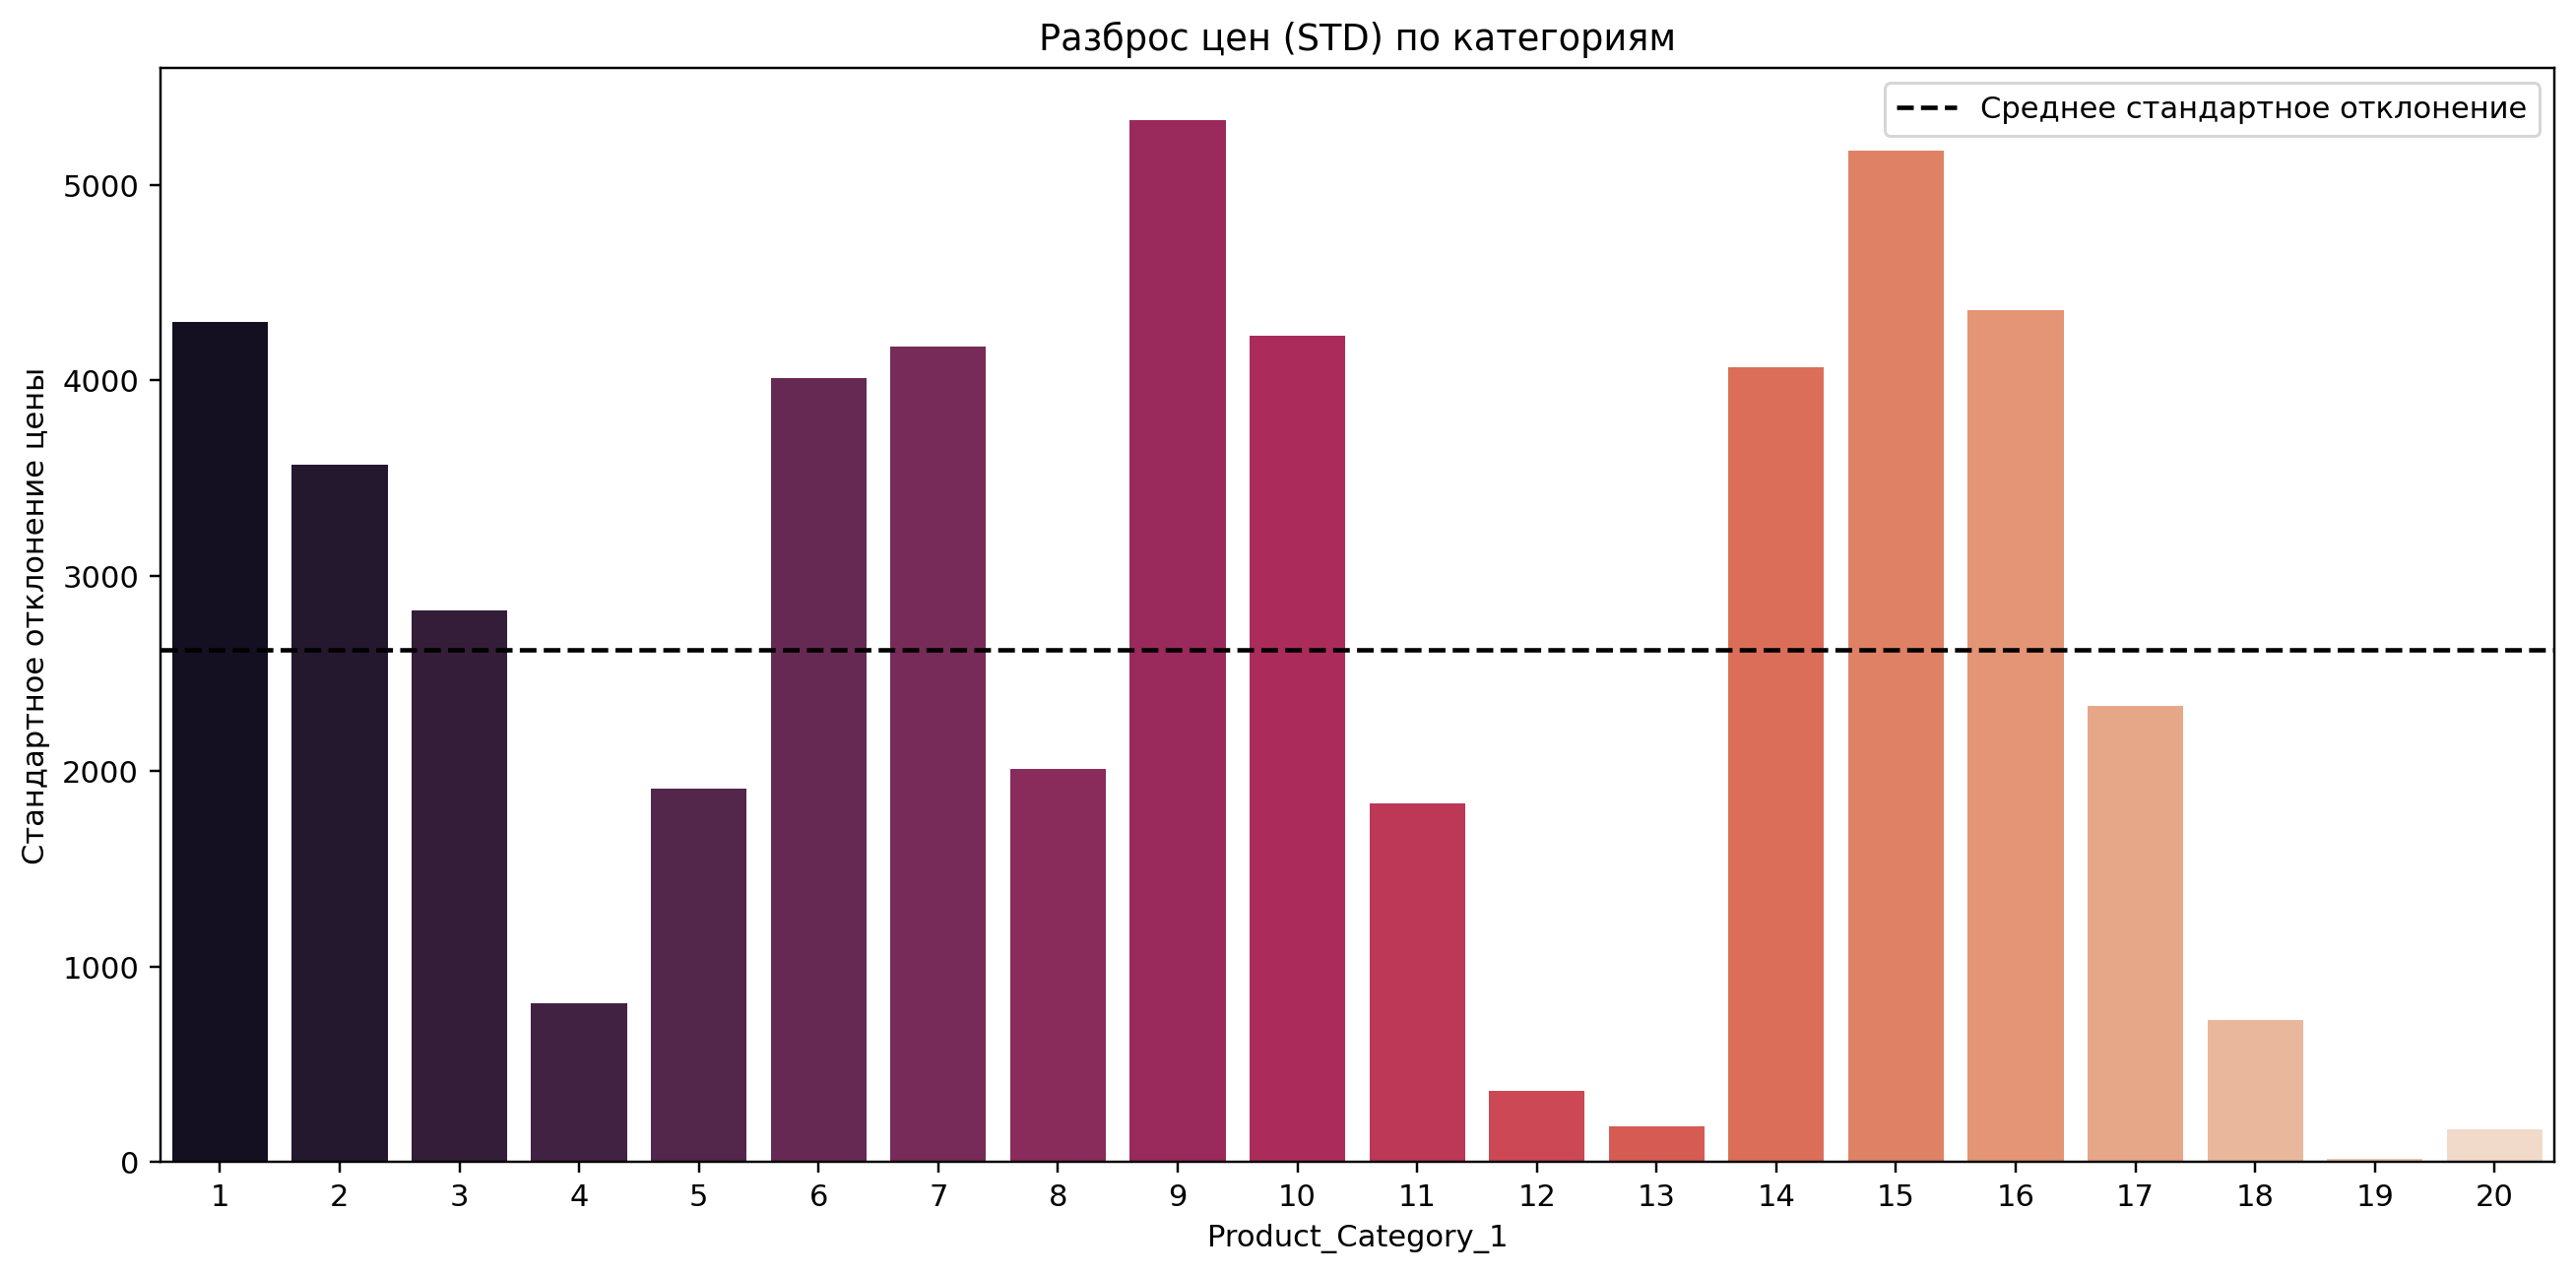

### age_cat1_heatmap.png

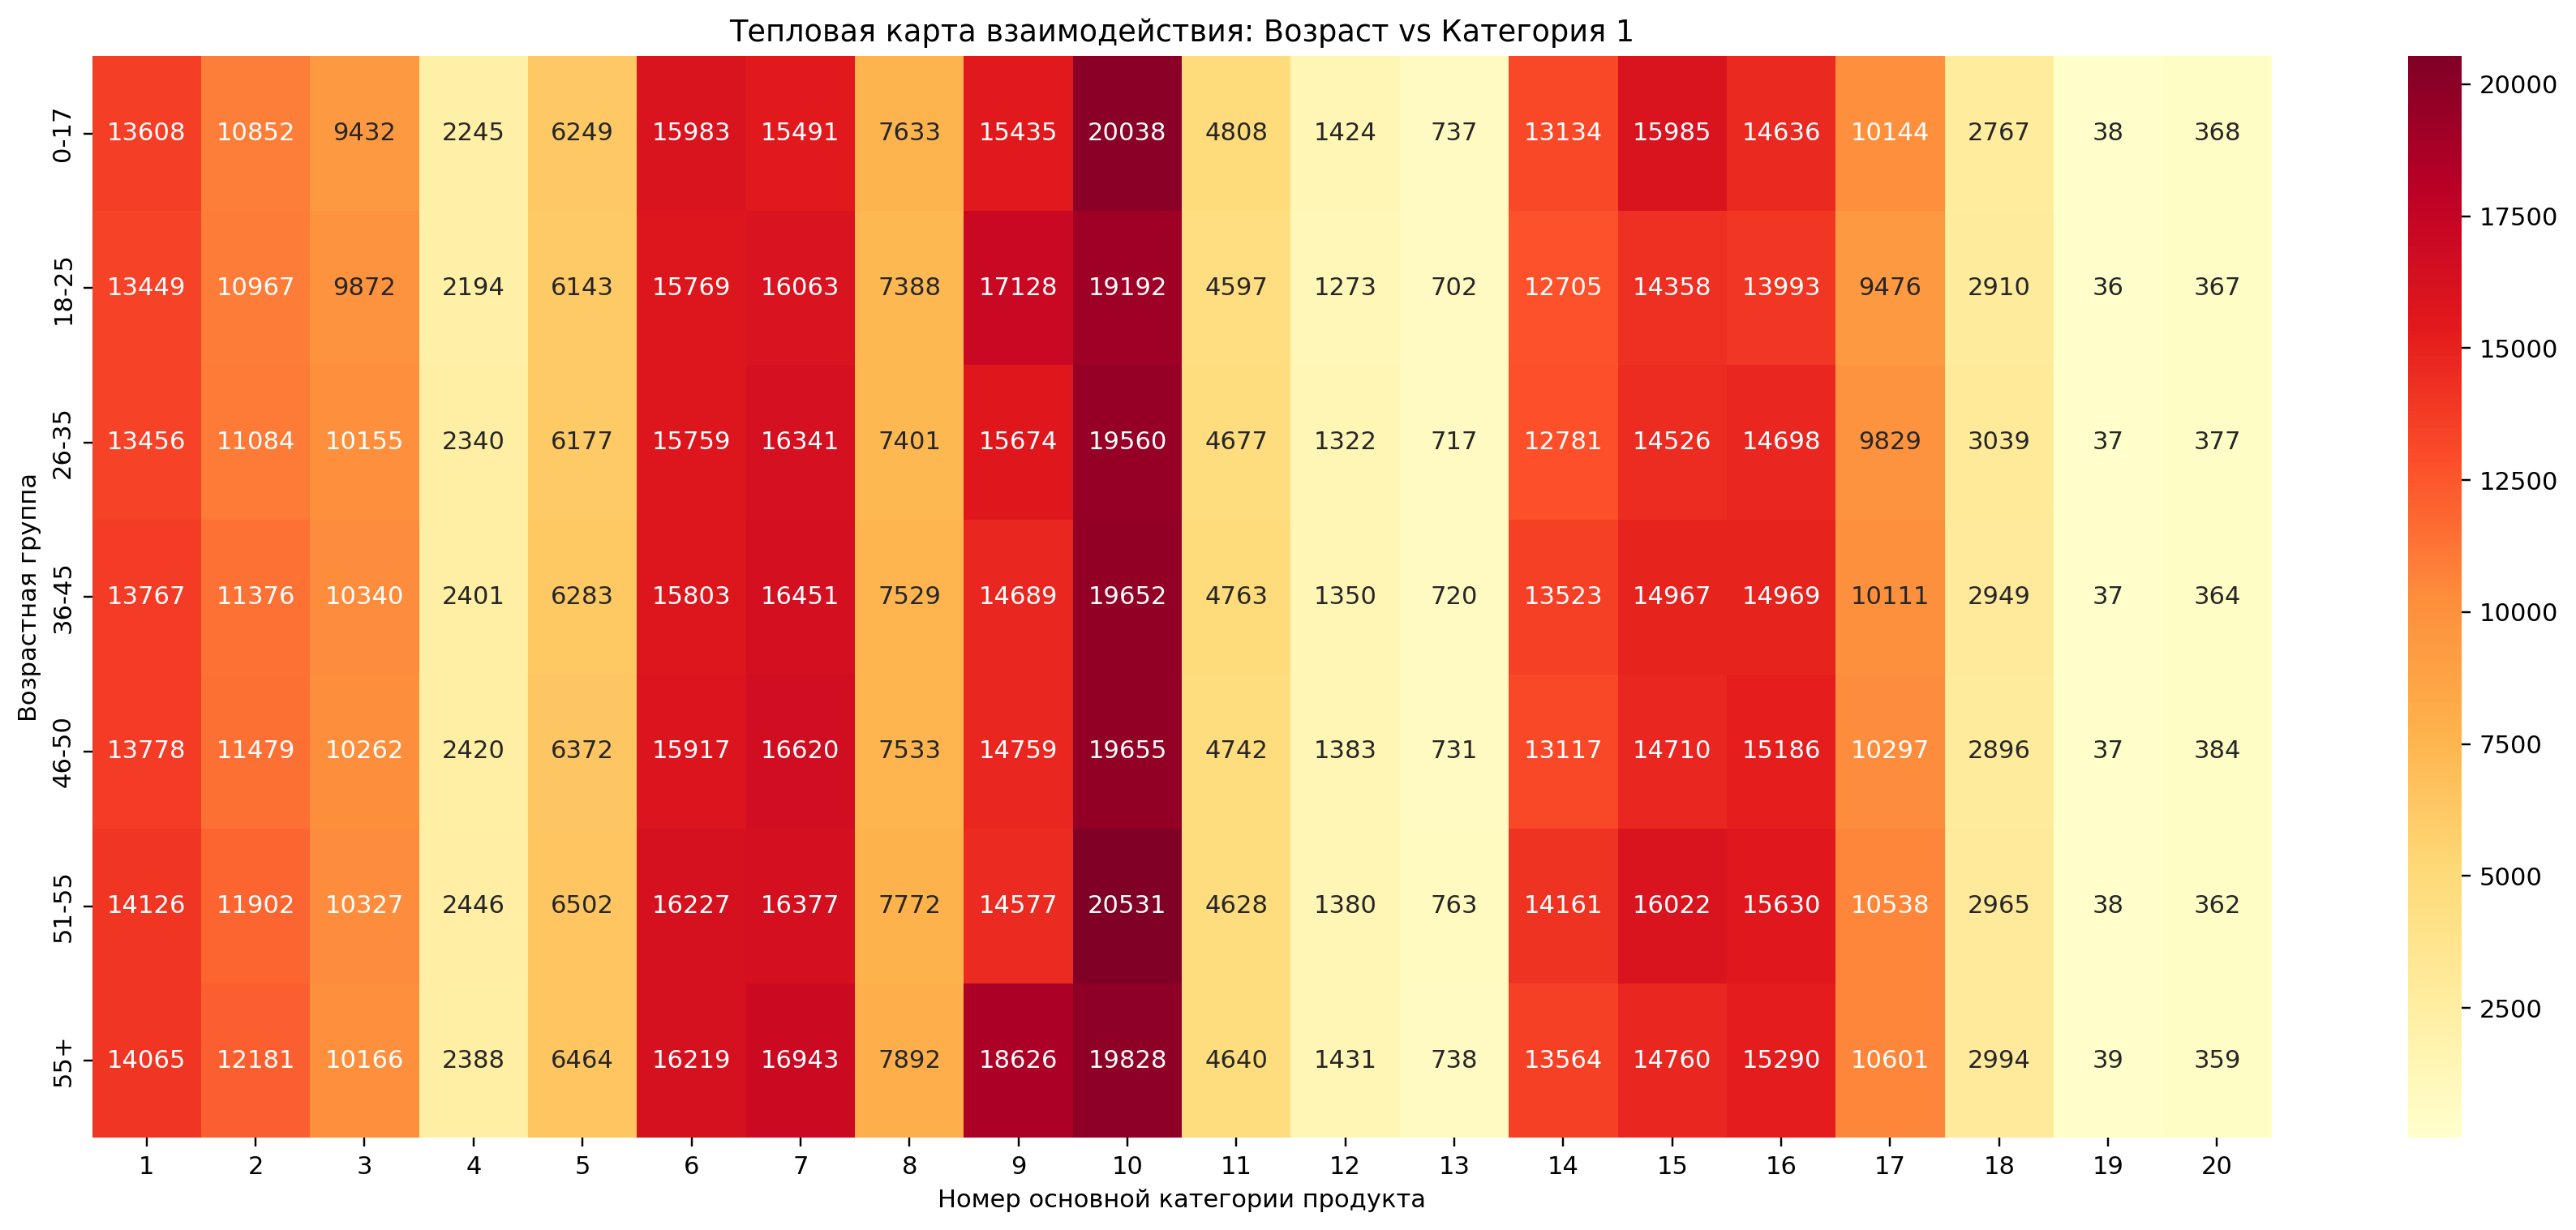

### city_gender_purchase.png

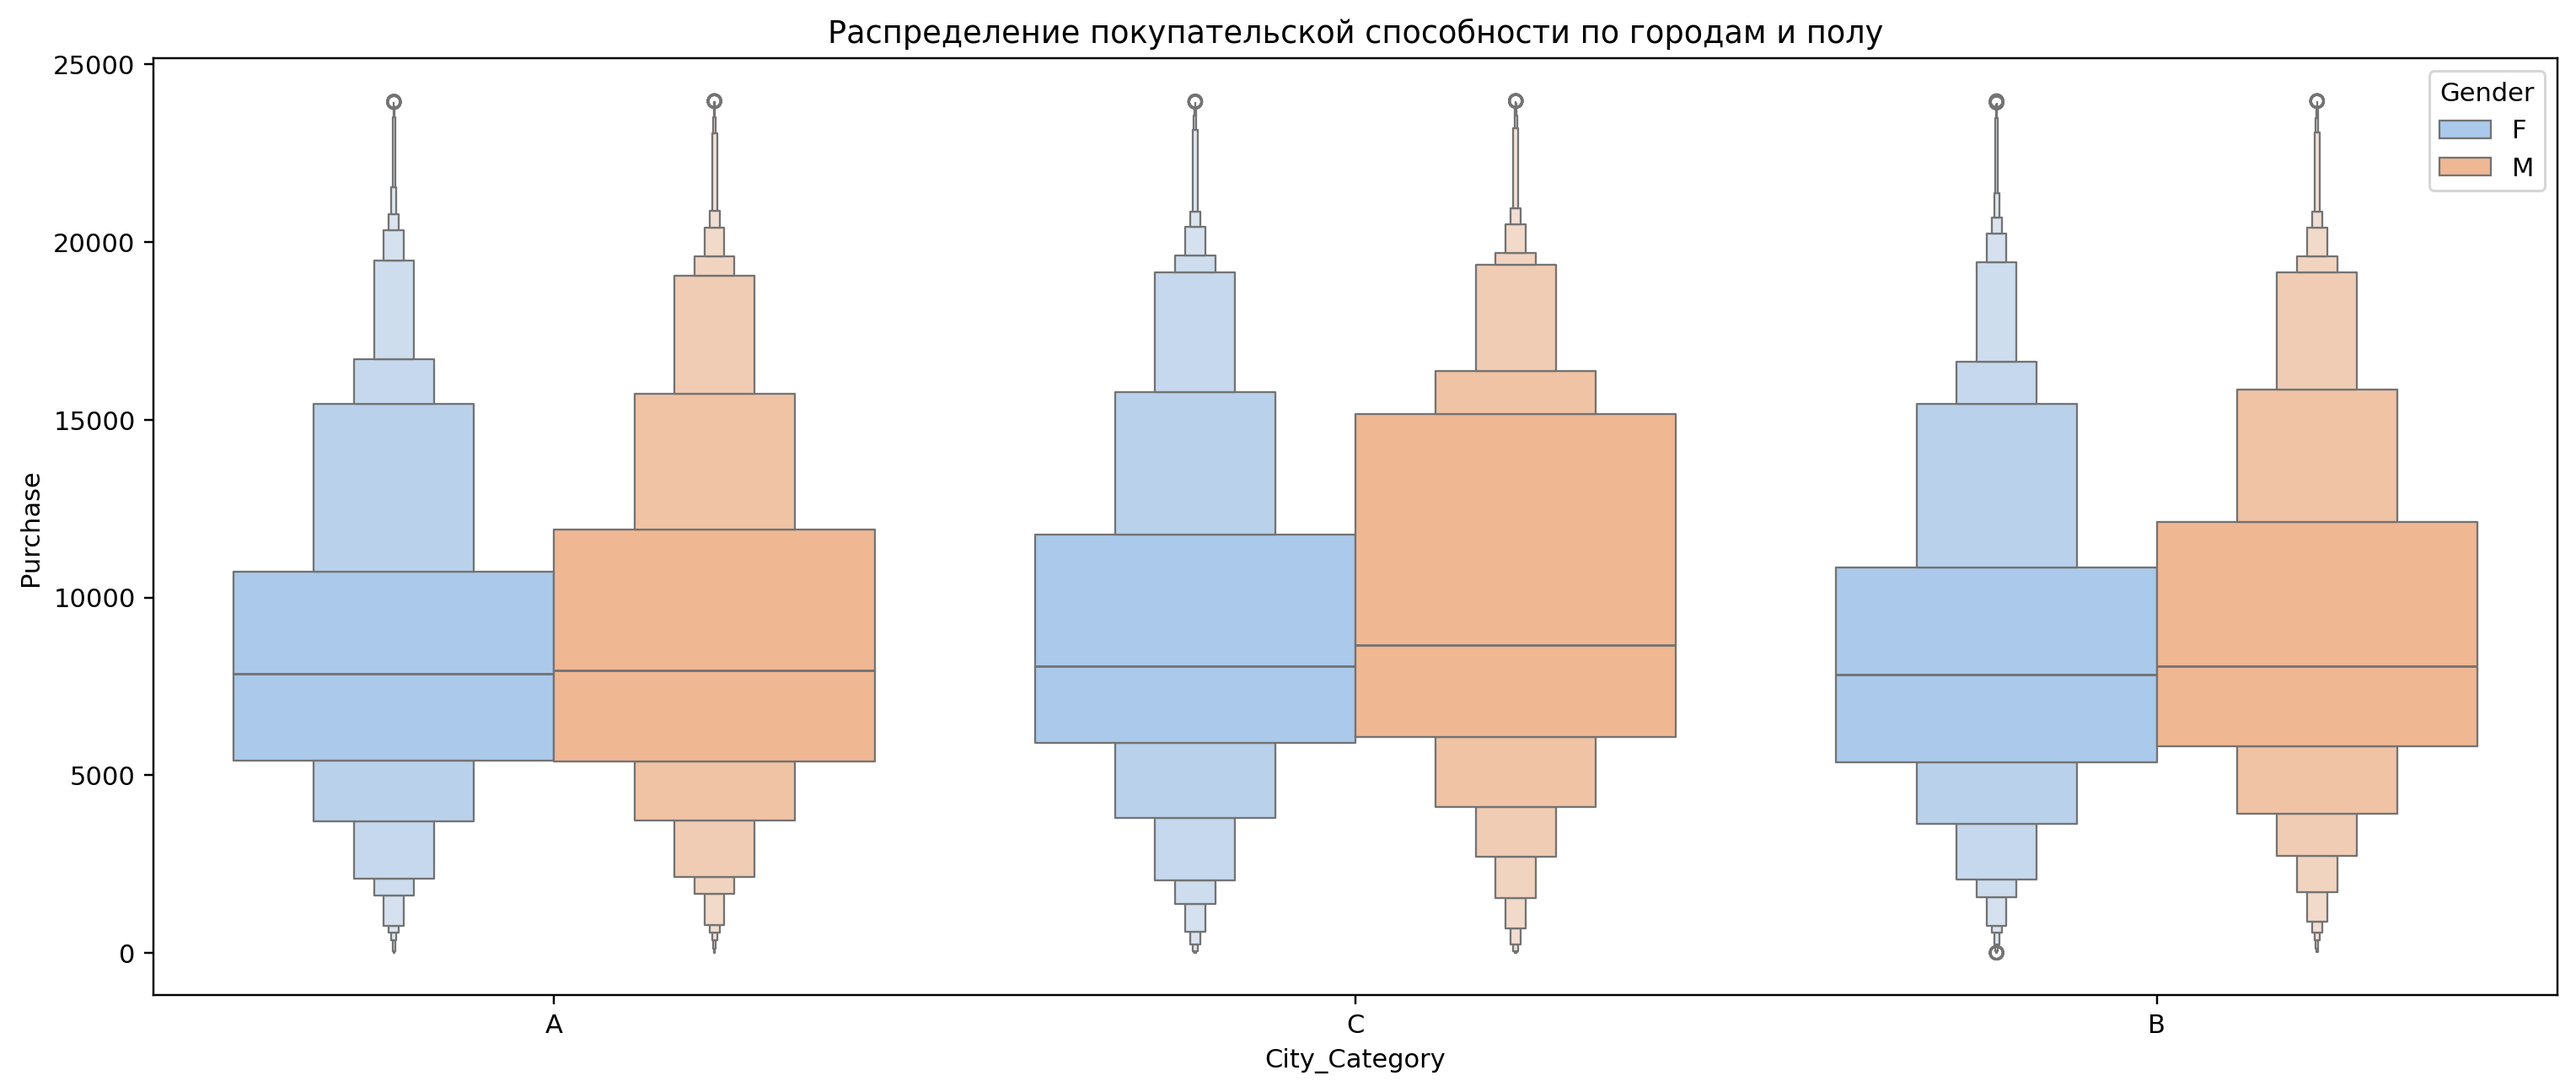

### user_segmentation_rfm.png

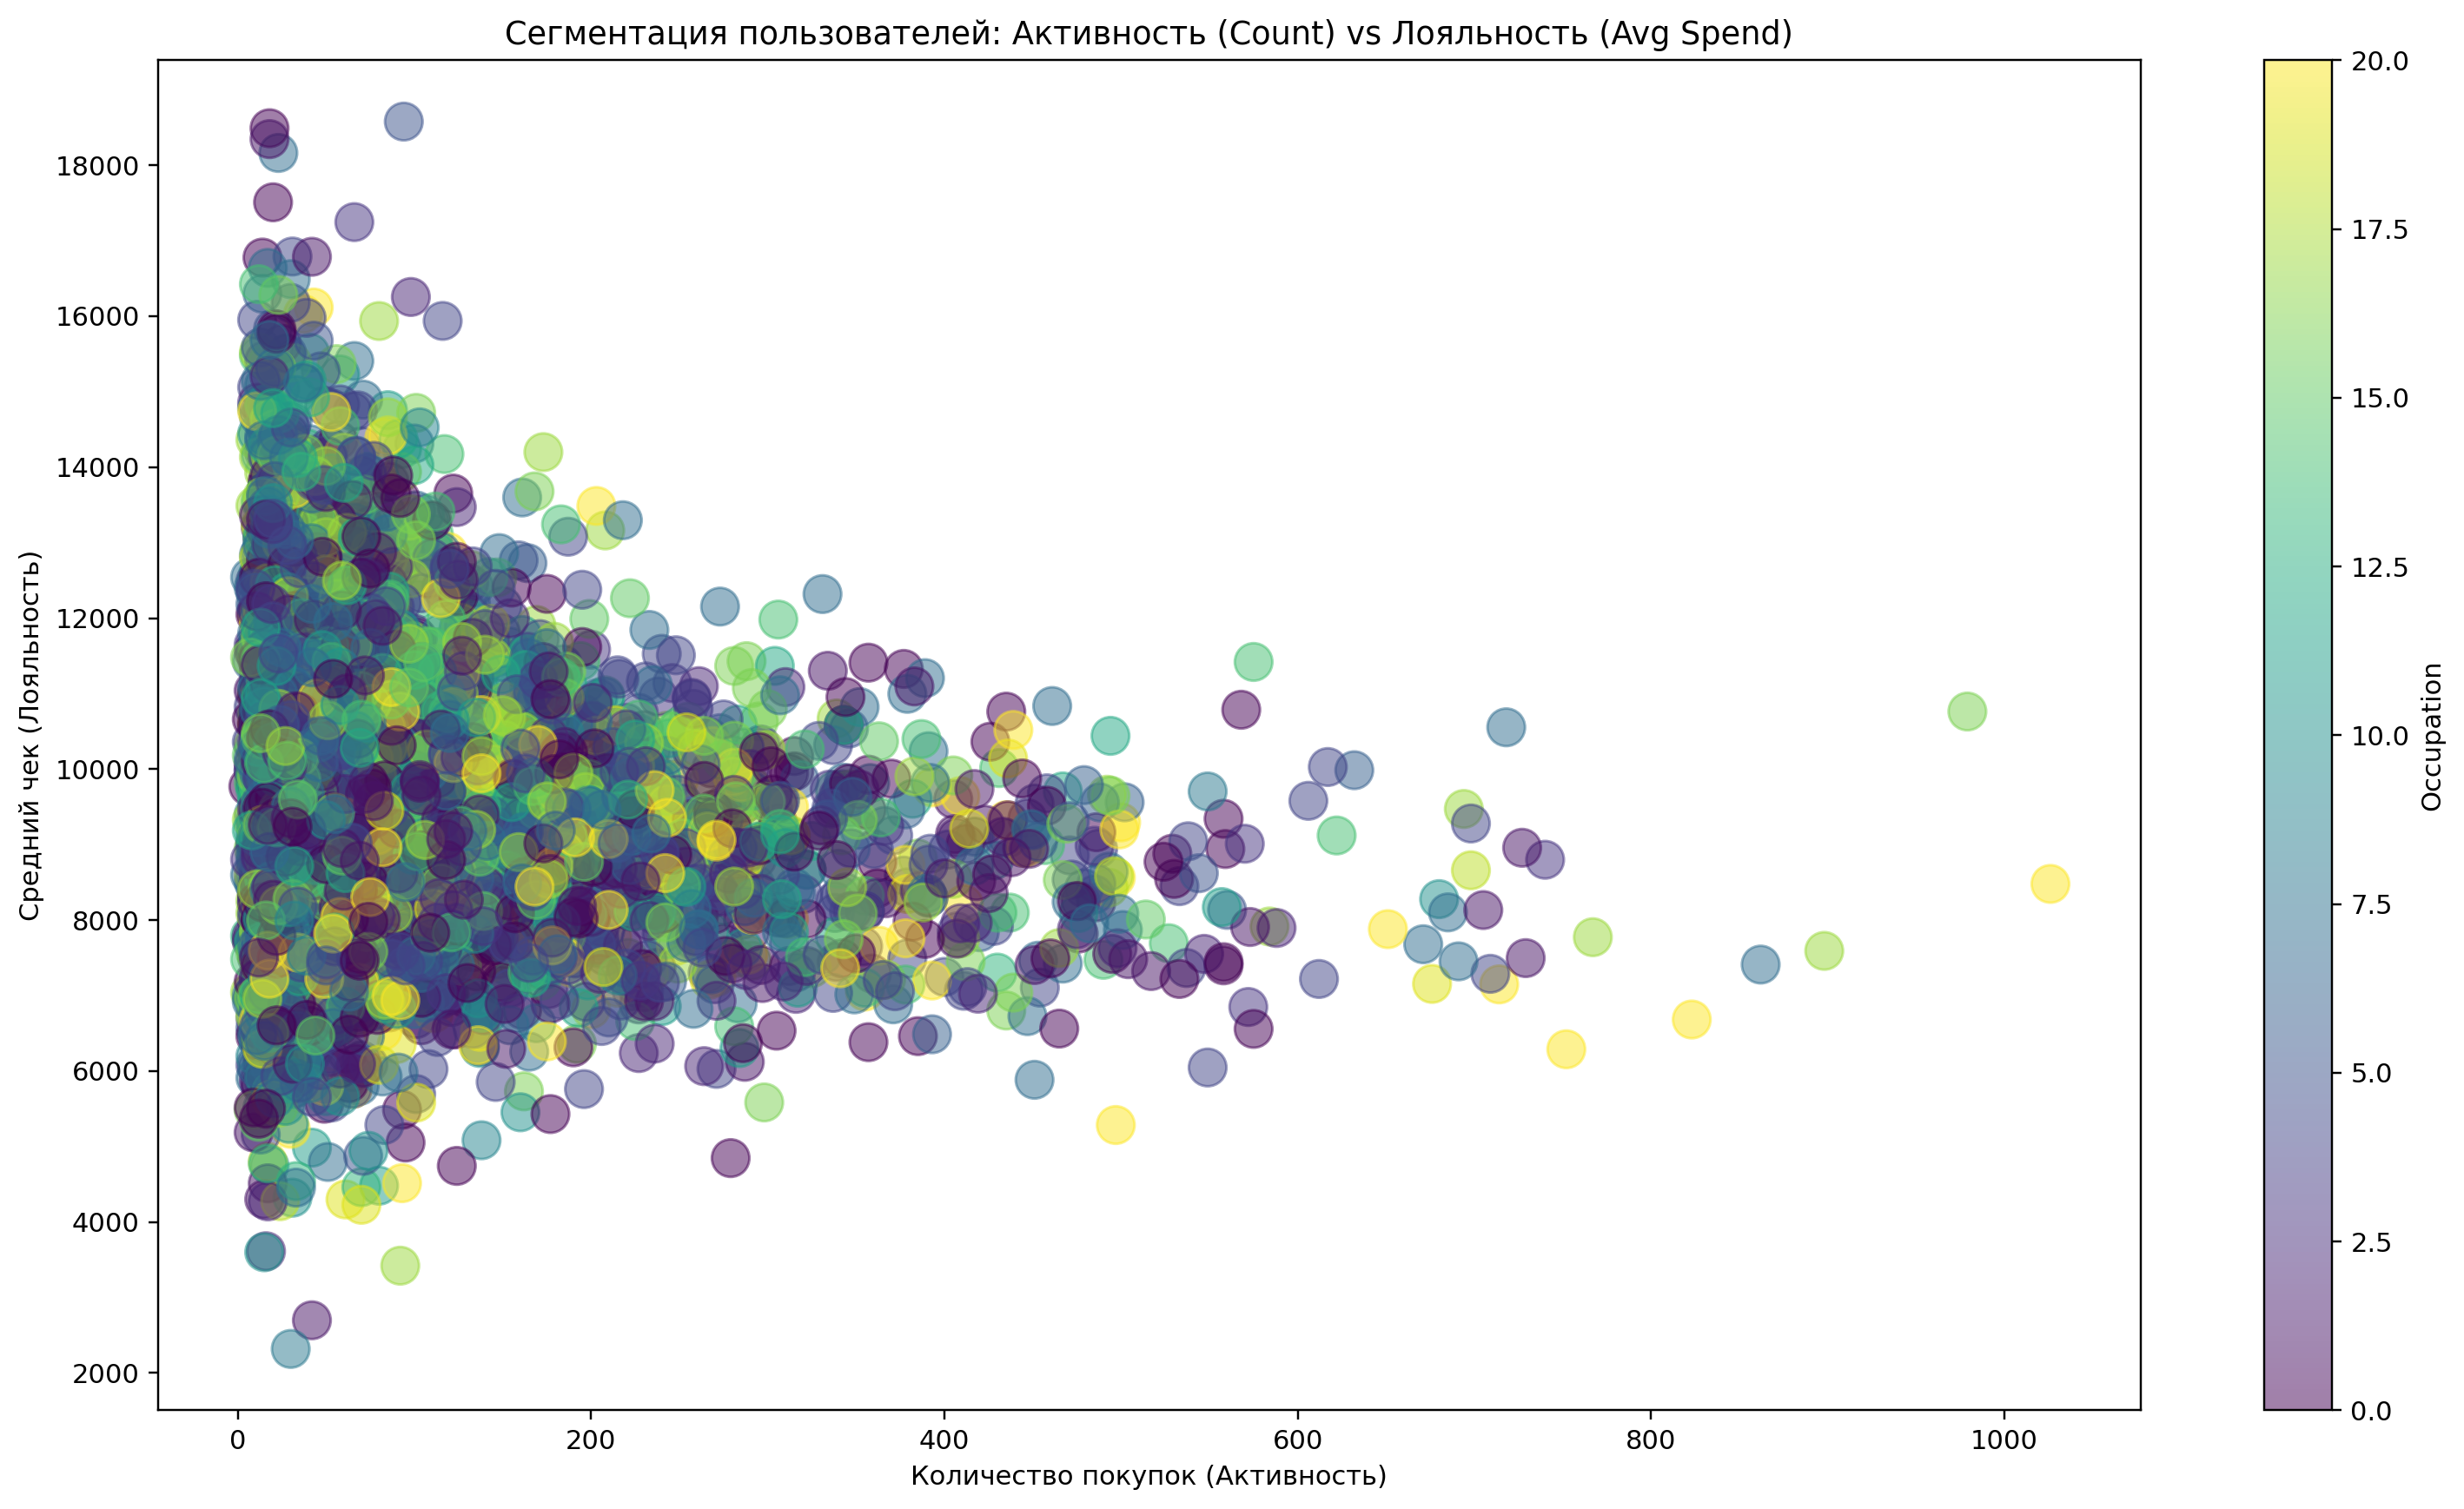

### occ_city_deviation.png

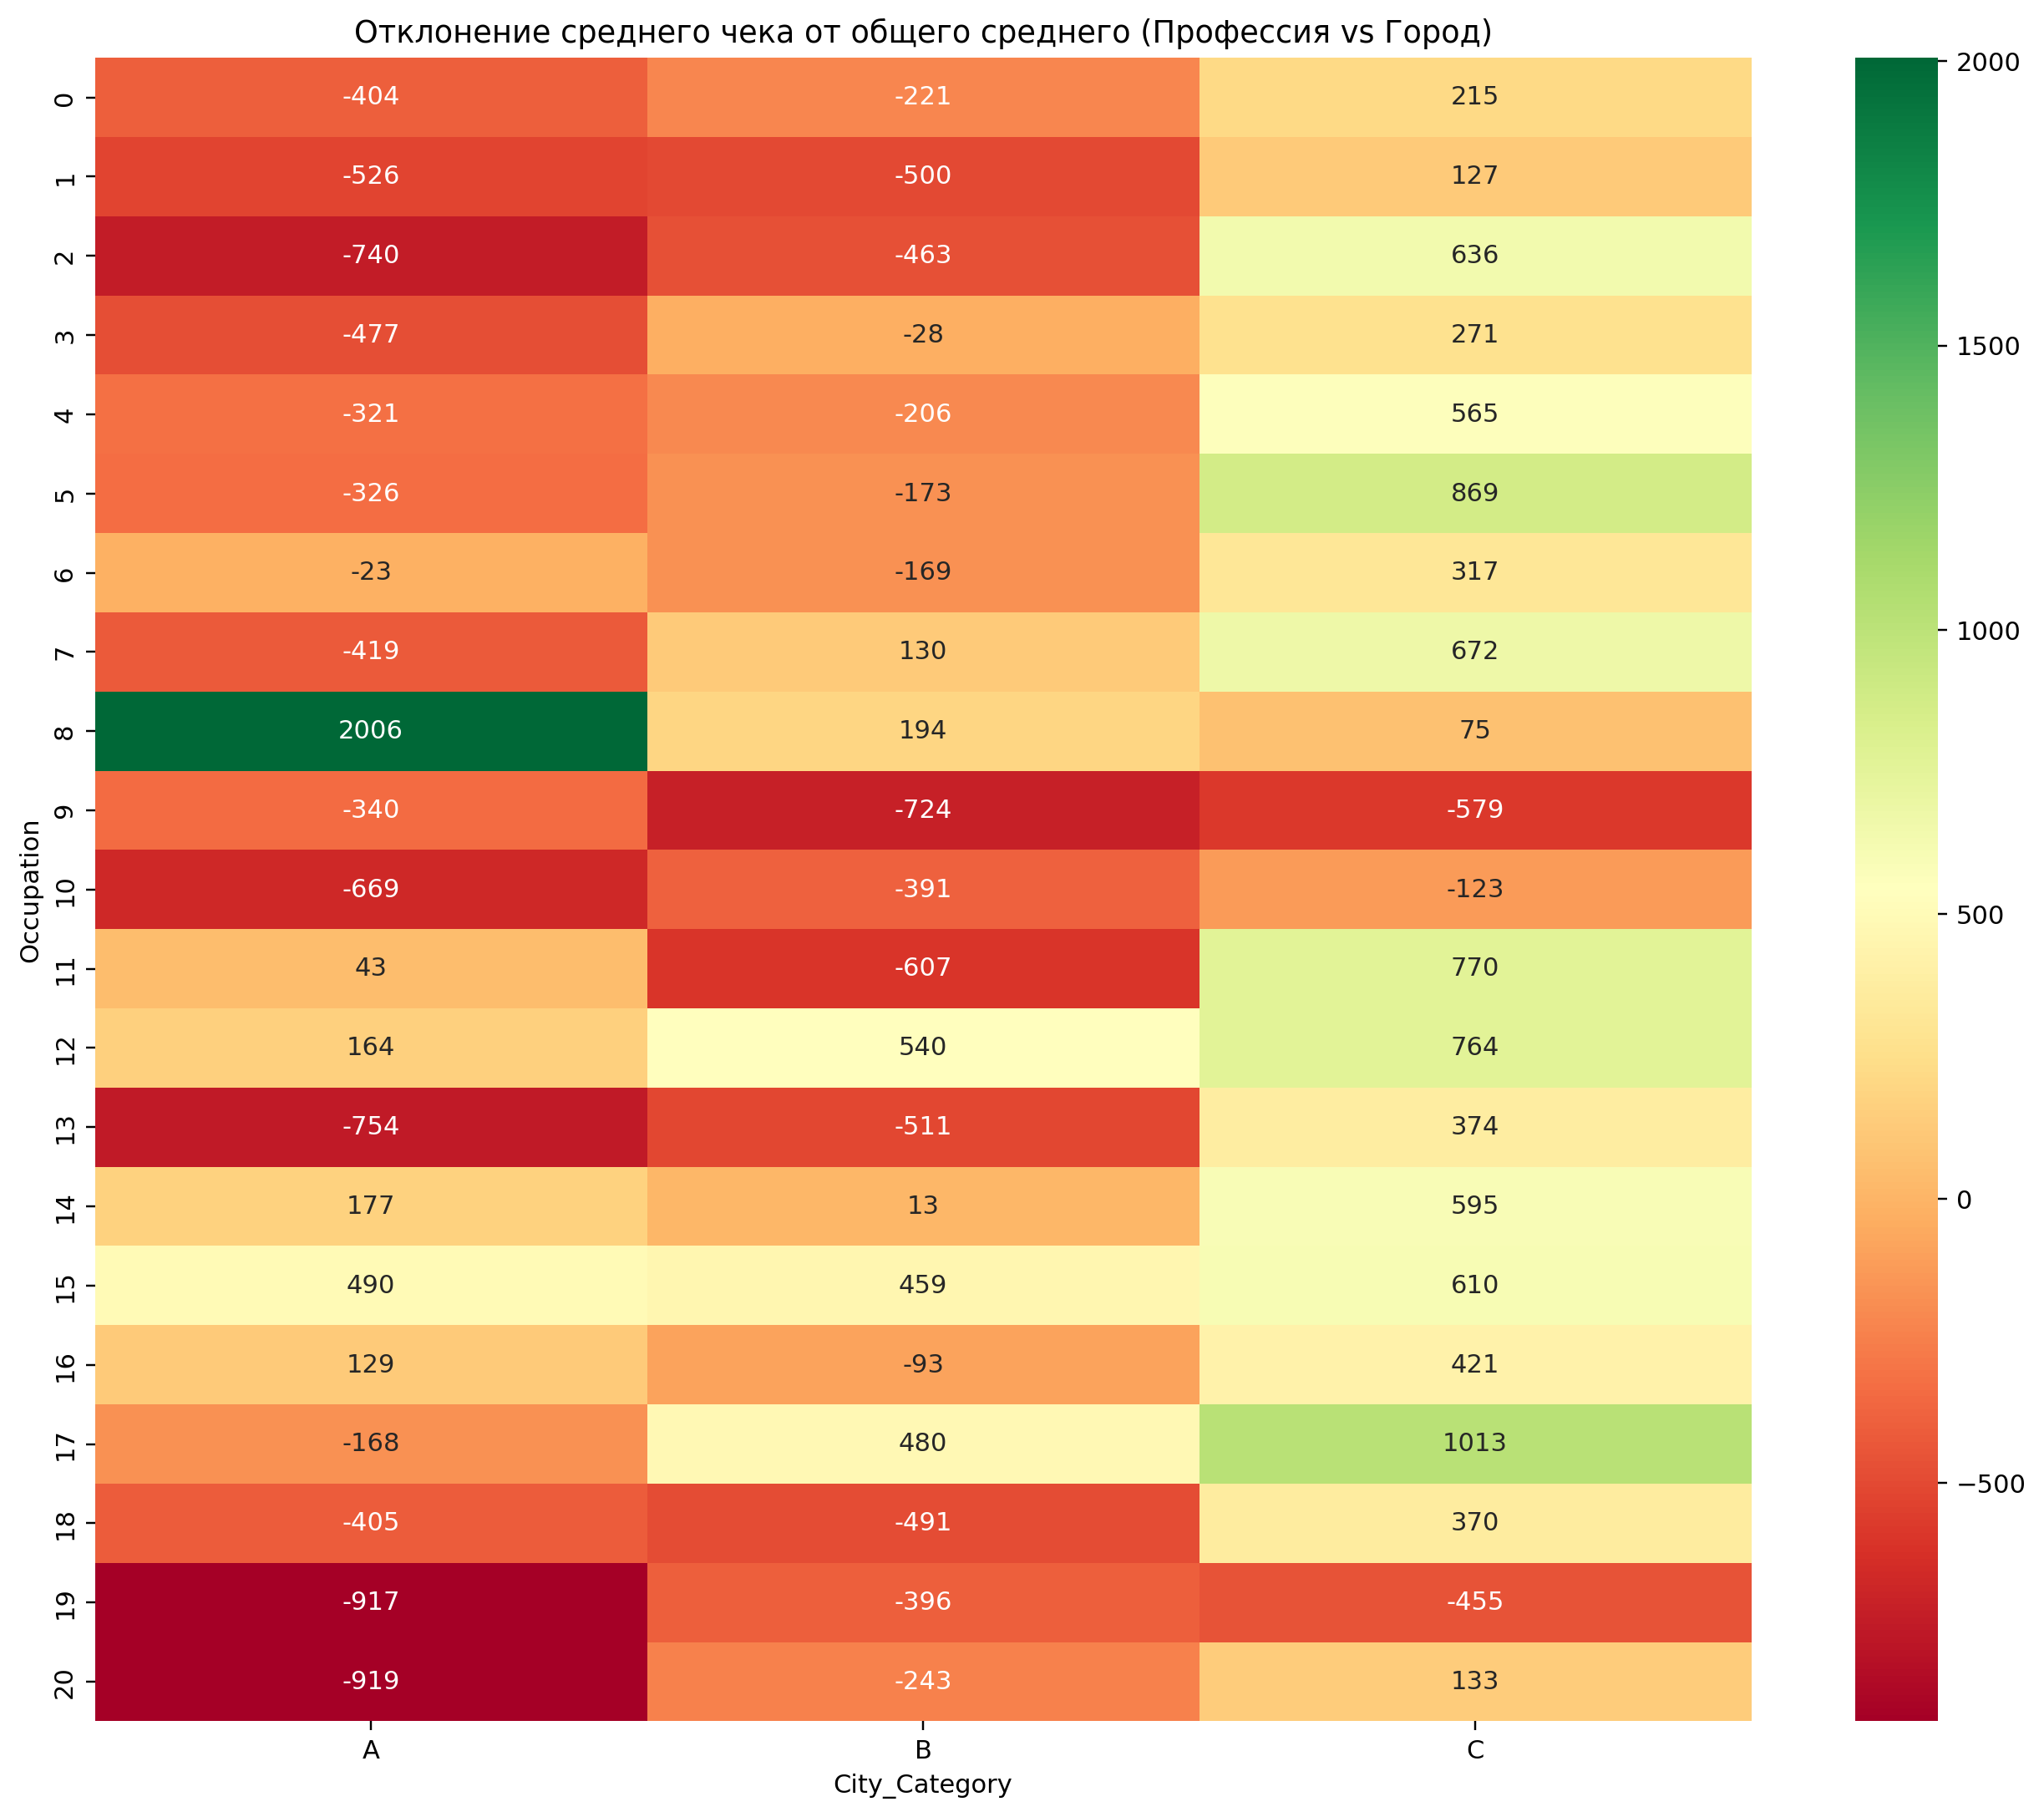

In [4]:
for image_name in [
    'volatility_by_cat.png',
    'age_cat1_heatmap.png',
    'city_gender_purchase.png',
    'user_segmentation_rfm.png',
    'occ_city_deviation.png',
]:
    display(Markdown(f'### {image_name}'))
    display(Image(filename=str(dirs['figures'] / image_name)))


## 4. Инженерия признаков

Признаки строятся в строго фиксированном порядке:
1. очистка пропусков;
2. порядковые и бинарные кодировки базовых полей;
3. частотные и структурные признаки из объединенного train+test;
4. интеракции пользователя, города, возраста и категорий;
5. OOF target encoding только после формирования базового feature-space.

In [5]:
train_fe, test_fe = build_feature_frames(train, test)
train_fe, test_fe = apply_target_encodings(train_fe, test_fe)
baseline_features, advanced_candidates = feature_sets(train_fe)
display(pd.DataFrame({
    'feature_space': ['baseline', 'advanced_candidates'],
    'count': [len(baseline_features), len(advanced_candidates)],
} ))
display(train_fe.head(3))


,feature_space,count
0,baseline,10
1,advanced_candidates,27


,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,...,Occupation_Gender,Purchase,User_ID_TE,Product_ID_TE,Category_Combo_TE,Product1_Marital_TE,Age_Occupation_TE,Product_Category_1_TE,Category_12_TE,Occupation_City_Gender_TE
0,1000001,684,0,0,10,0,2,0,3,NaN,...,2,8370,9527.272944,11613.174489,11553.894509,10021.535888,8844.890449,10087.694818,11553.894509,7742.450788
1,1000001,2406,0,0,10,0,2,0,1,6.0,...,2,15200,9624.293352,16019.480356,15355.732499,13583.636286,8839.577966,13601.627687,14262.298536,7829.970974
2,1000001,868,0,0,10,0,2,0,12,NaN,...,2,1422,9575.630539,2728.207169,1435.198750,1440.968582,8884.972413,1401.478323,1435.198750,7959.309234


## 5. Статистический отбор и согласование итогового списка признаков

В отличие от поздних версий исходного ноутбука, здесь нет двух конкурирующих списков `final_features`.
Сначала вычисляется статистический ranking, затем к нему добавляется небольшой набор must-have признаков из сильных бизнес-гипотез и OOF target encoding.

In [6]:
ranking = compute_statistical_ranking(train_fe, advanced_candidates, dirs['figures'])
selected_features = select_features(ranking, train_fe)
display(ranking.head(20))
display(pd.Series(selected_features, name='selected_feature'))


,feature,mutual_info,f_score,rf_importance,mutual_info_rank,f_score_rank,rf_importance_rank,mean_rank
0,Product_ID_TE,1.176470,71652.495164,0.825587,7.0,1.0,1.0,3.000000
1,Category_Combo_TE,1.575260,55612.152181,0.009979,5.0,2.0,6.0,4.333333
2,Category_12_TE,1.643828,52094.796671,0.008124,4.0,3.0,9.0,5.333333
3,Product1_Marital_TE,1.651472,50091.811739,0.007792,3.0,5.0,10.0,6.000000
4,Product_Popularity,0.599863,3503.749157,0.011695,8.0,7.0,3.0,6.000000
5,Product_Category_1_TE,1.653055,50094.246457,0.004099,2.0,4.0,16.0,7.333333
6,Product_City_Freq,0.329510,3058.790347,0.010002,10.0,10.0,5.0,8.333333
7,Product_Category_1,1.658475,3725.257697,0.001458,1.0,6.0,21.0,9.333333
8,User_ID_TE,0.063940,2716.853372,0.045089,16.0,12.0,2.0,10.000000
9,User_Cat_Freq,0.292136,306.006753,0.010967,11.0,16.0,4.0,10.333333


0                     User_ID_TE
1                  Product_ID_TE
2              Category_Combo_TE
3            Product1_Marital_TE
4              Age_Occupation_TE
5          Product_Category_1_TE
6                 Category_12_TE
7      Occupation_City_Gender_TE
8             Product_Popularity
9                  User_Cat_Freq
10             User_Total_Orders
11          User_Unique_Products
12             Product_City_Freq
13                Category_Count
14                   Age_Ordinal
15                  Stay_Ordinal
16                  City_Ordinal
17            Product_Category_1
18     Product_Category_2_filled
19     Product_Category_3_filled
20    Product_Category_2_missing
21    Product_Category_3_missing
22                    Occupation
23                Marital_Status
24                 Gender_Binary
25           Category_Combo_Freq
26              User_Unique_Cat1
Name: selected_feature, dtype: object

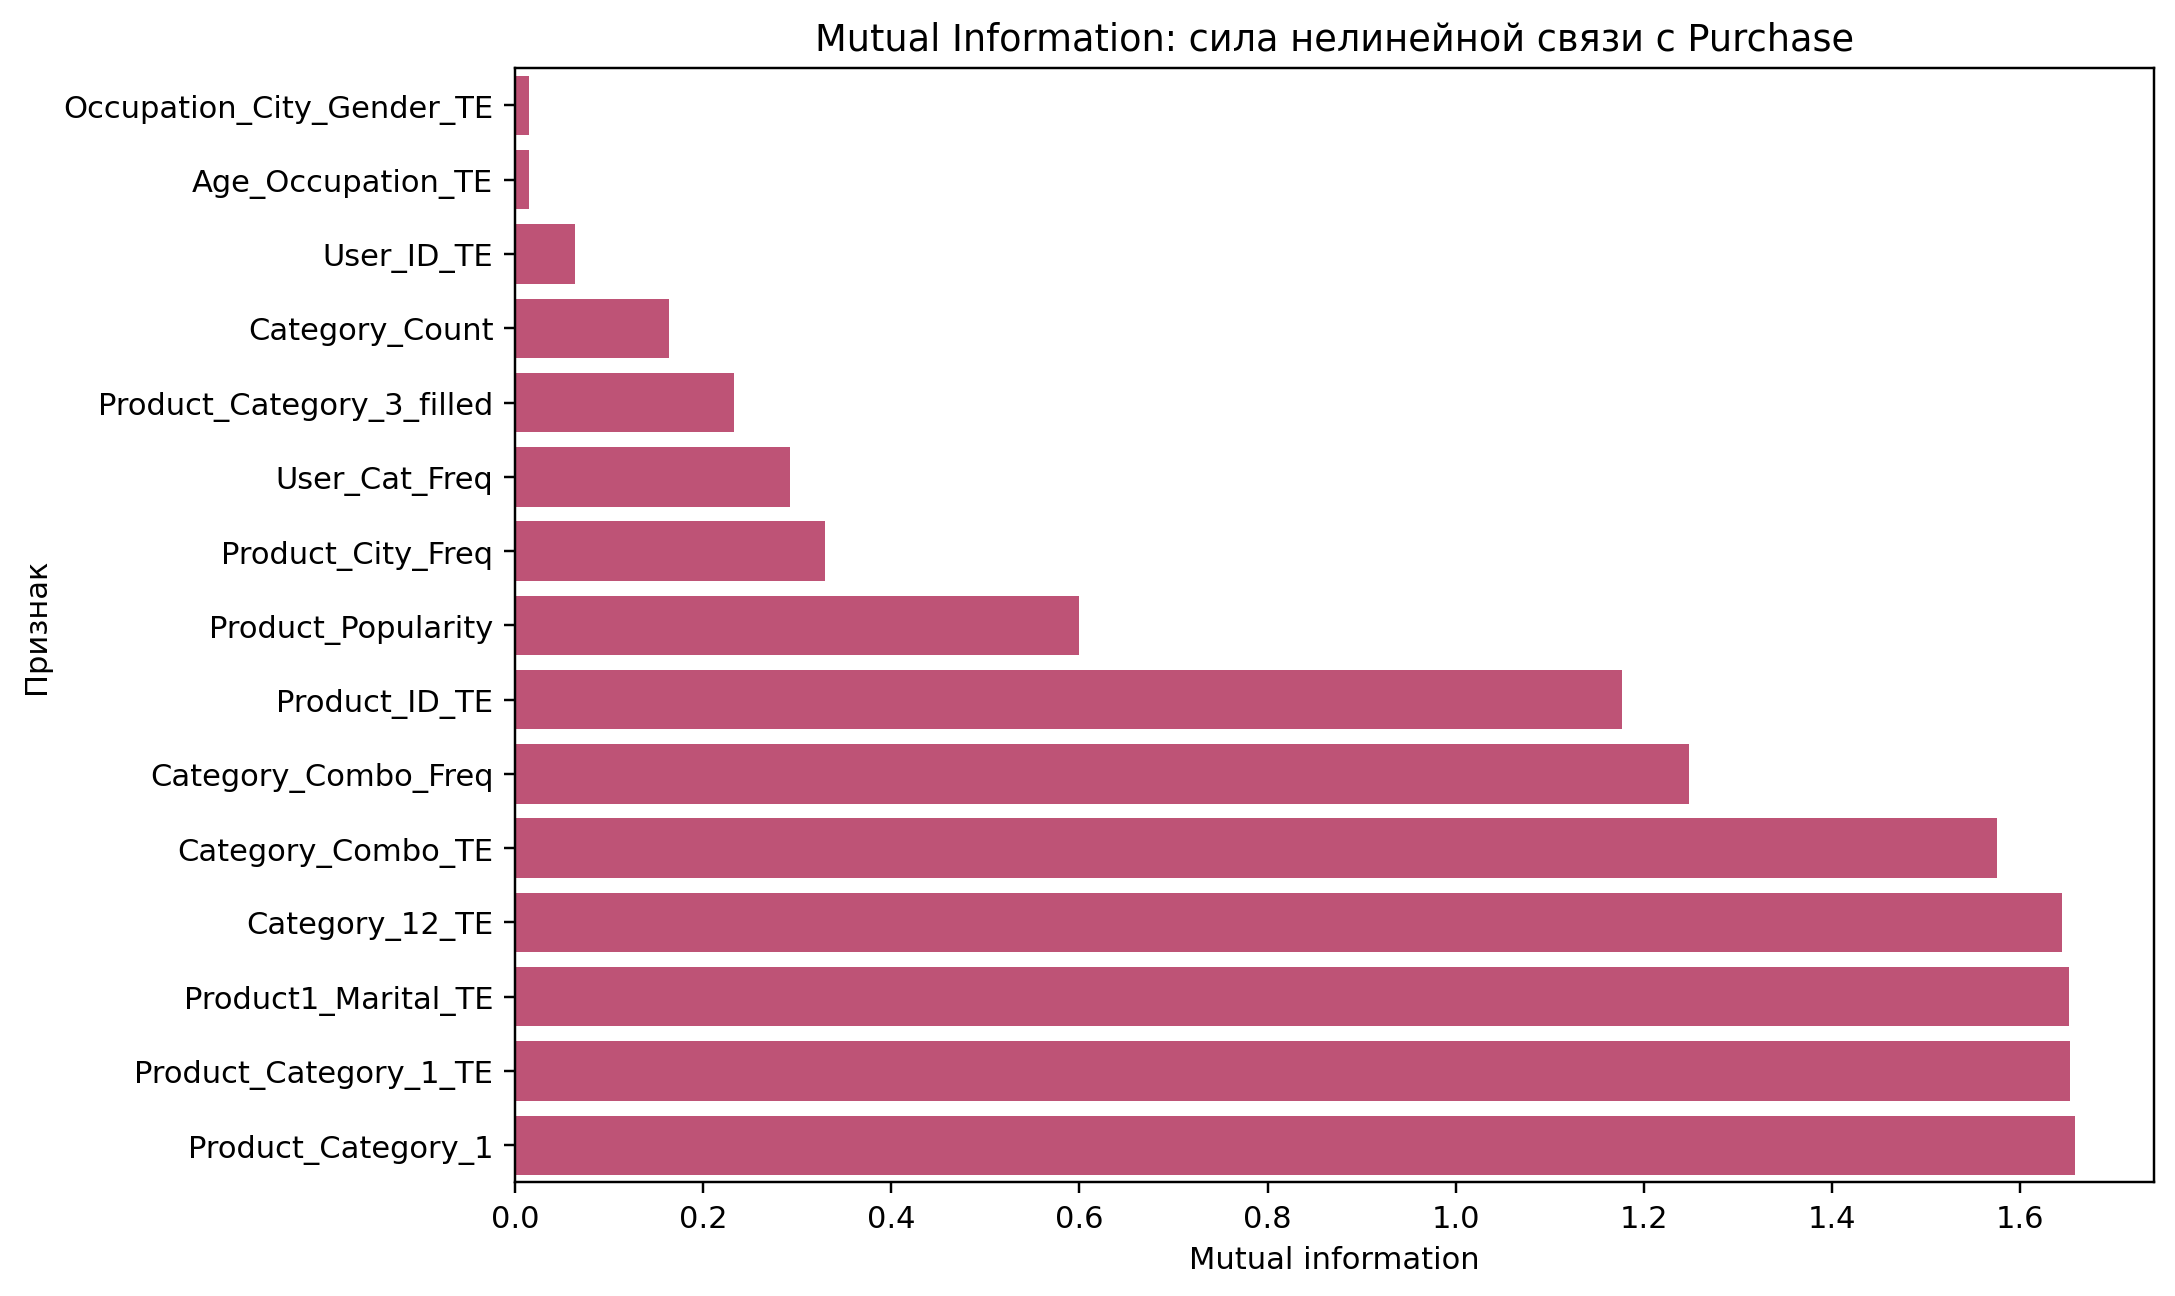

In [7]:
display(Image(filename=str(dirs['figures'] / 'eda_mutual_info.png')))


## 6. Проверка воспроизводимости

Ниже показан способ пересчитать все артефакты с нуля. По умолчанию ноутбук использует уже рассчитанные результаты из `results.json`, чтобы не дублировать тяжелое CV-обучение при каждом открытии файла.

In [8]:
# Тяжелый пересчет с нуля при необходимости:
# results = run_pipeline(TRAIN_PATH, TEST_PATH, OUTPUT_ROOT)
if results is None:
    results = run_pipeline(TRAIN_PATH, TEST_PATH, OUTPUT_ROOT)
results['ensemble']


{'weights': {'LightGBM': 0.75, 'XGBoost': 0.25},
 'rmse': 2469.9098130001366,
 'r2': 0.7582172480245932,
 'mape': 27.793419322900853,
 'best_importance_model': 'LightGBM',
 'test_mean_prediction': 9326.626238120252}

## 7. Сравнение моделей

In [9]:
models_df = pd.DataFrame(results['model_results'])[['name', 'rmse', 'r2', 'mape']]
models_df = pd.concat([
    models_df,
    pd.DataFrame([{
        'name': 'Final Ensemble',
        'rmse': results['ensemble']['rmse'],
        'r2': results['ensemble']['r2'],
        'mape': results['ensemble']['mape'],
    }])
], ignore_index=True)
display(models_df.round(4))


,name,rmse,r2,mape
0,BaselineHGB,2892.4931,0.6684,35.3116
1,LightGBM,2471.0177,0.7580,27.8605
2,XGBoost,2481.8514,0.7559,27.9137
3,Final Ensemble,2469.9098,0.7582,27.7934


## 8. Интерпретация признаков и качества

In [10]:
importance_model_name = results['ensemble']['best_importance_model'].lower()
importance_df = pd.read_csv(OUTPUT_ROOT / f'{importance_model_name}_importance.csv')
display(importance_df.head(15))


,feature,importance
0,User_ID_TE,13098.8
1,User_Total_Orders,11408.0
2,Product_ID_TE,10233.8
3,User_Cat_Freq,9055.6
4,Occupation_City_Gender_TE,8879.6
5,Age_Occupation_TE,8724.2
6,Product_Popularity,7273.6
7,Product_City_Freq,7114.6
8,Category_Combo_TE,6954.4
9,Category_12_TE,5580.6


## 9. Диагностика ансамбля

In [11]:
display(results['ensemble'])
display(results['diagnostics'])


{'weights': {'LightGBM': 0.75, 'XGBoost': 0.25},
 'rmse': 2469.9098130001366,
 'r2': 0.7582172480245932,
 'mape': 27.793419322900853,
 'best_importance_model': 'LightGBM',
 'test_mean_prediction': 9326.626238120252}

{'error_popularity_corr': -0.06701961738222174}

### rmse_improvement_comparison.png

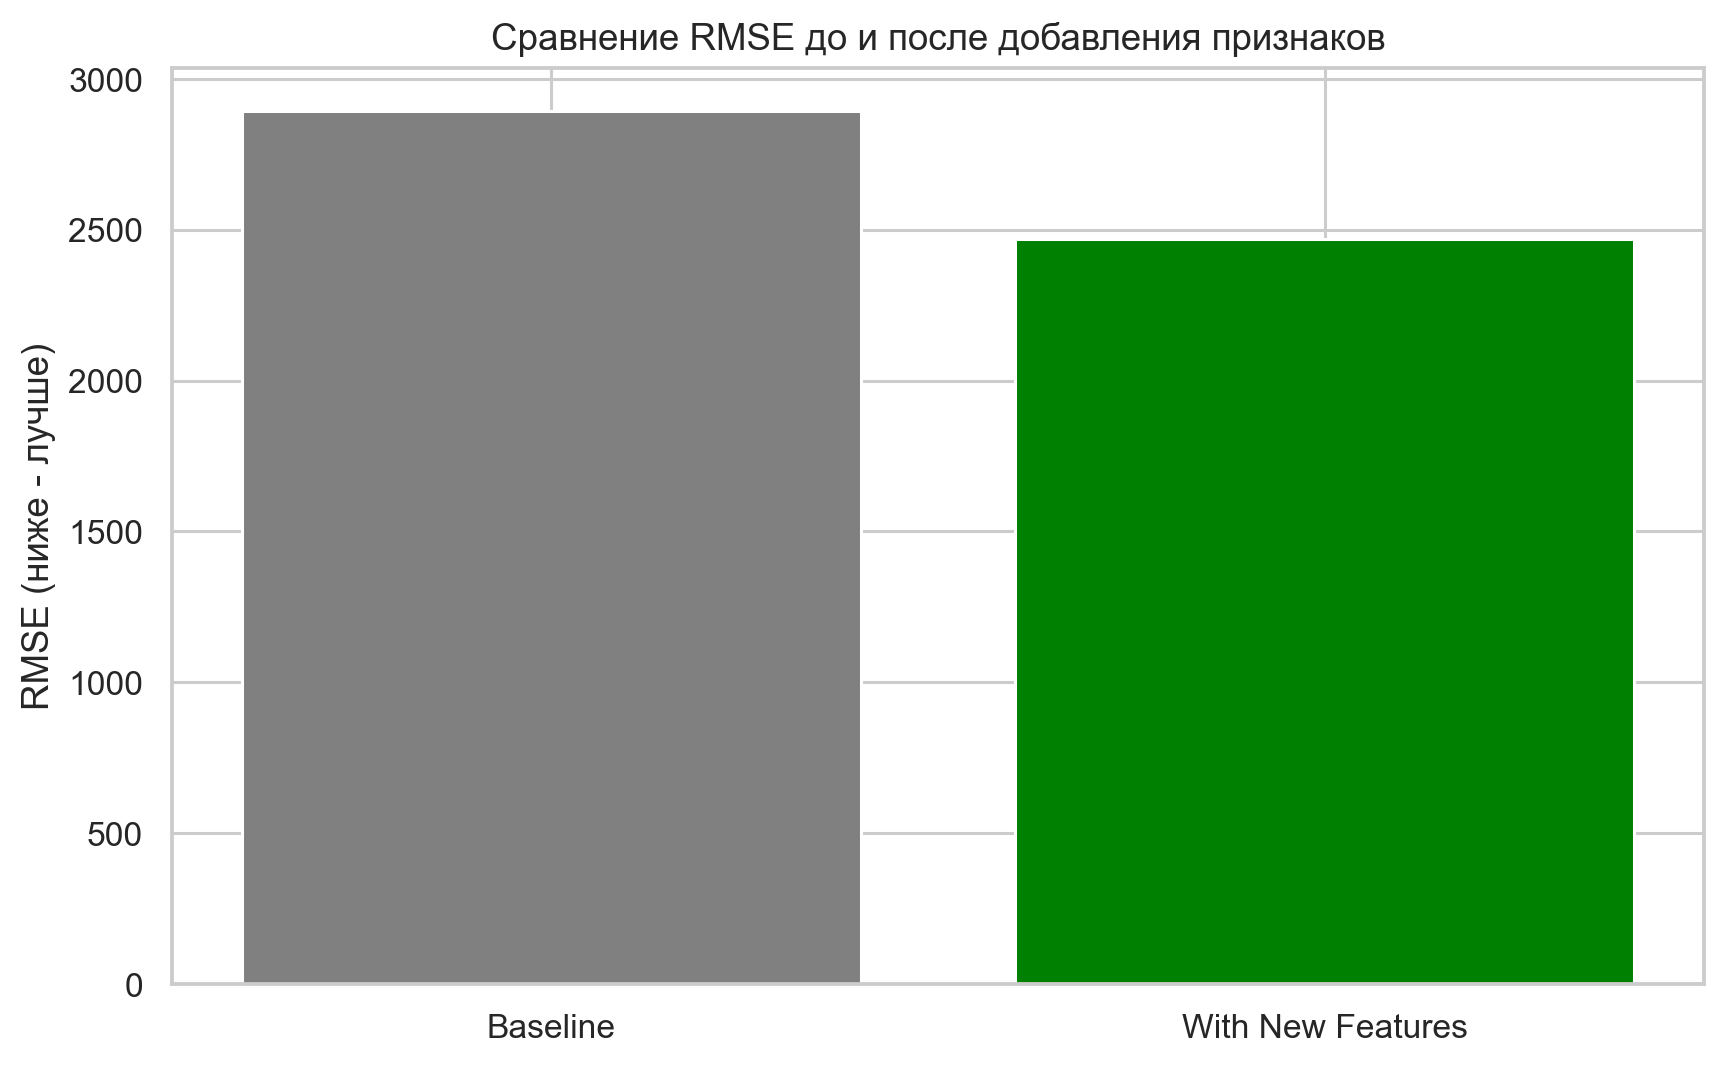

### feature_importance_comparison.png

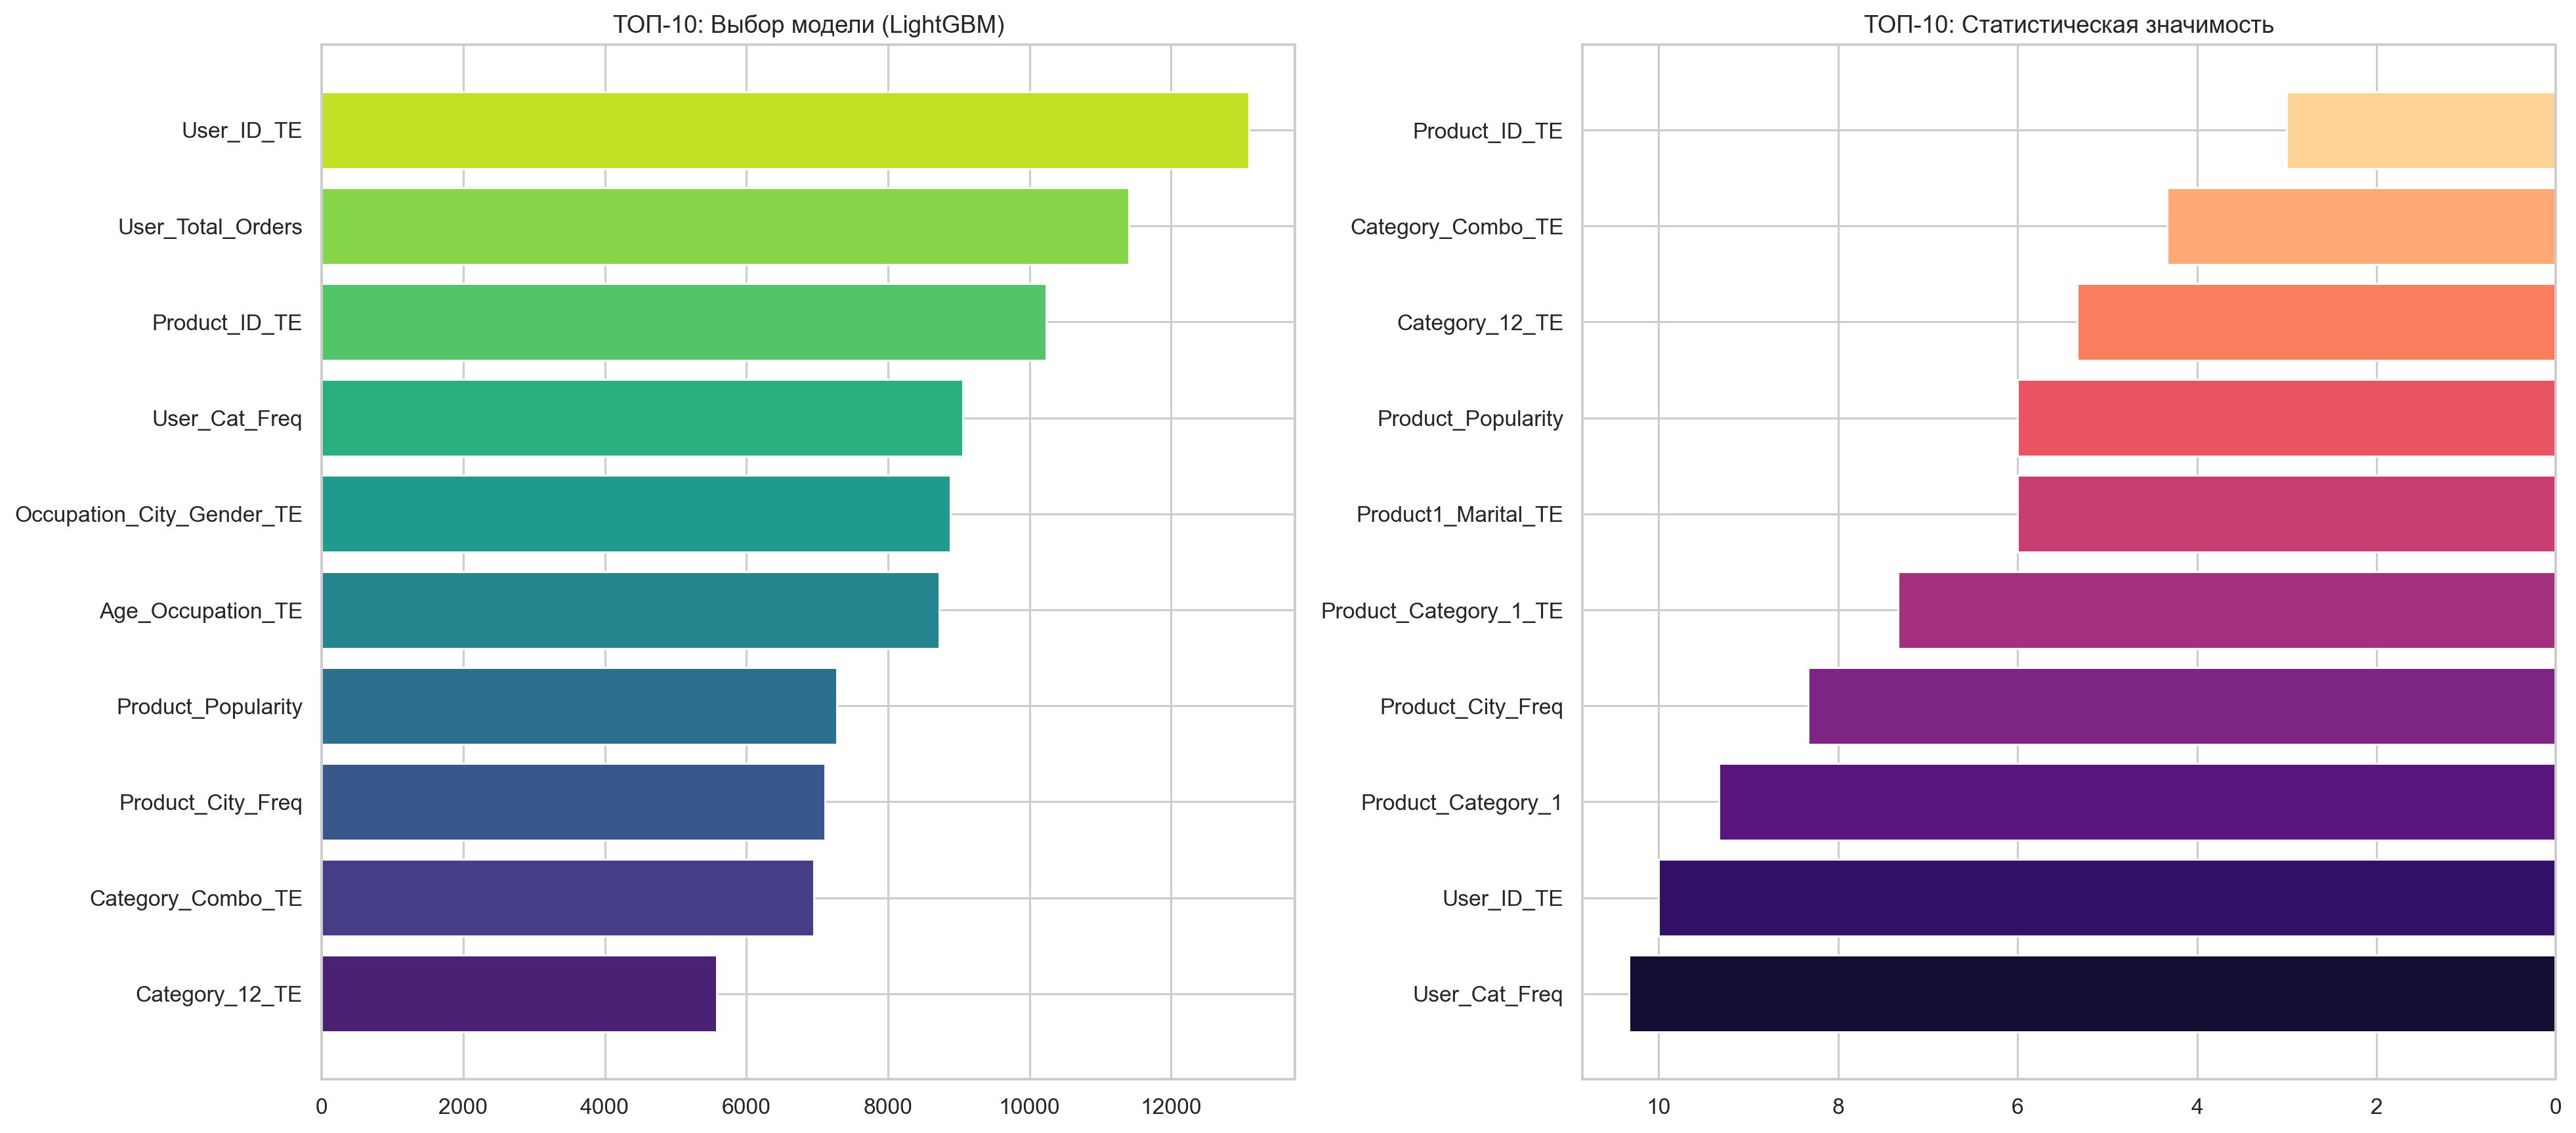

### final_ensemble_performance.png

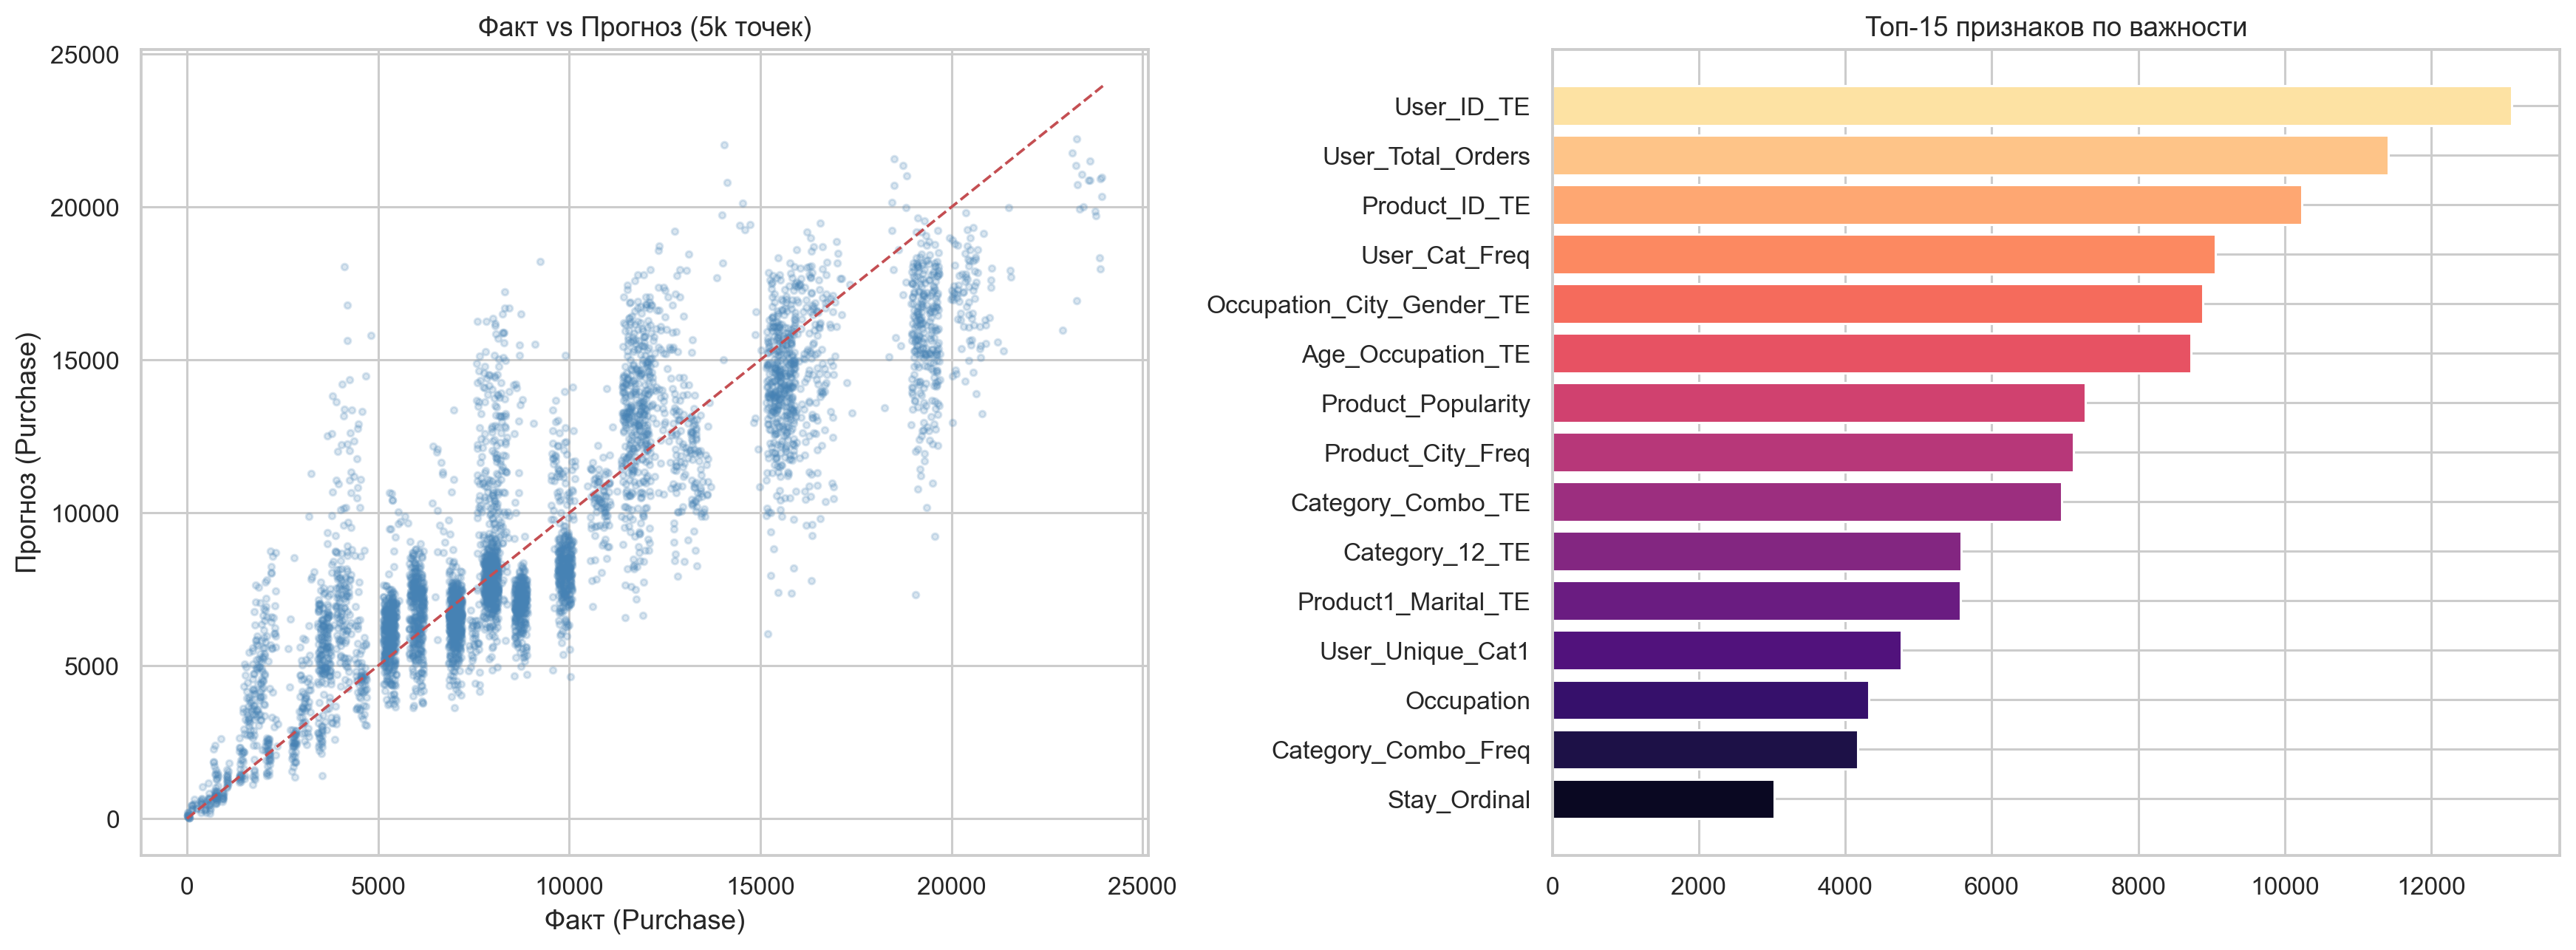

### error_vs_popularity.png

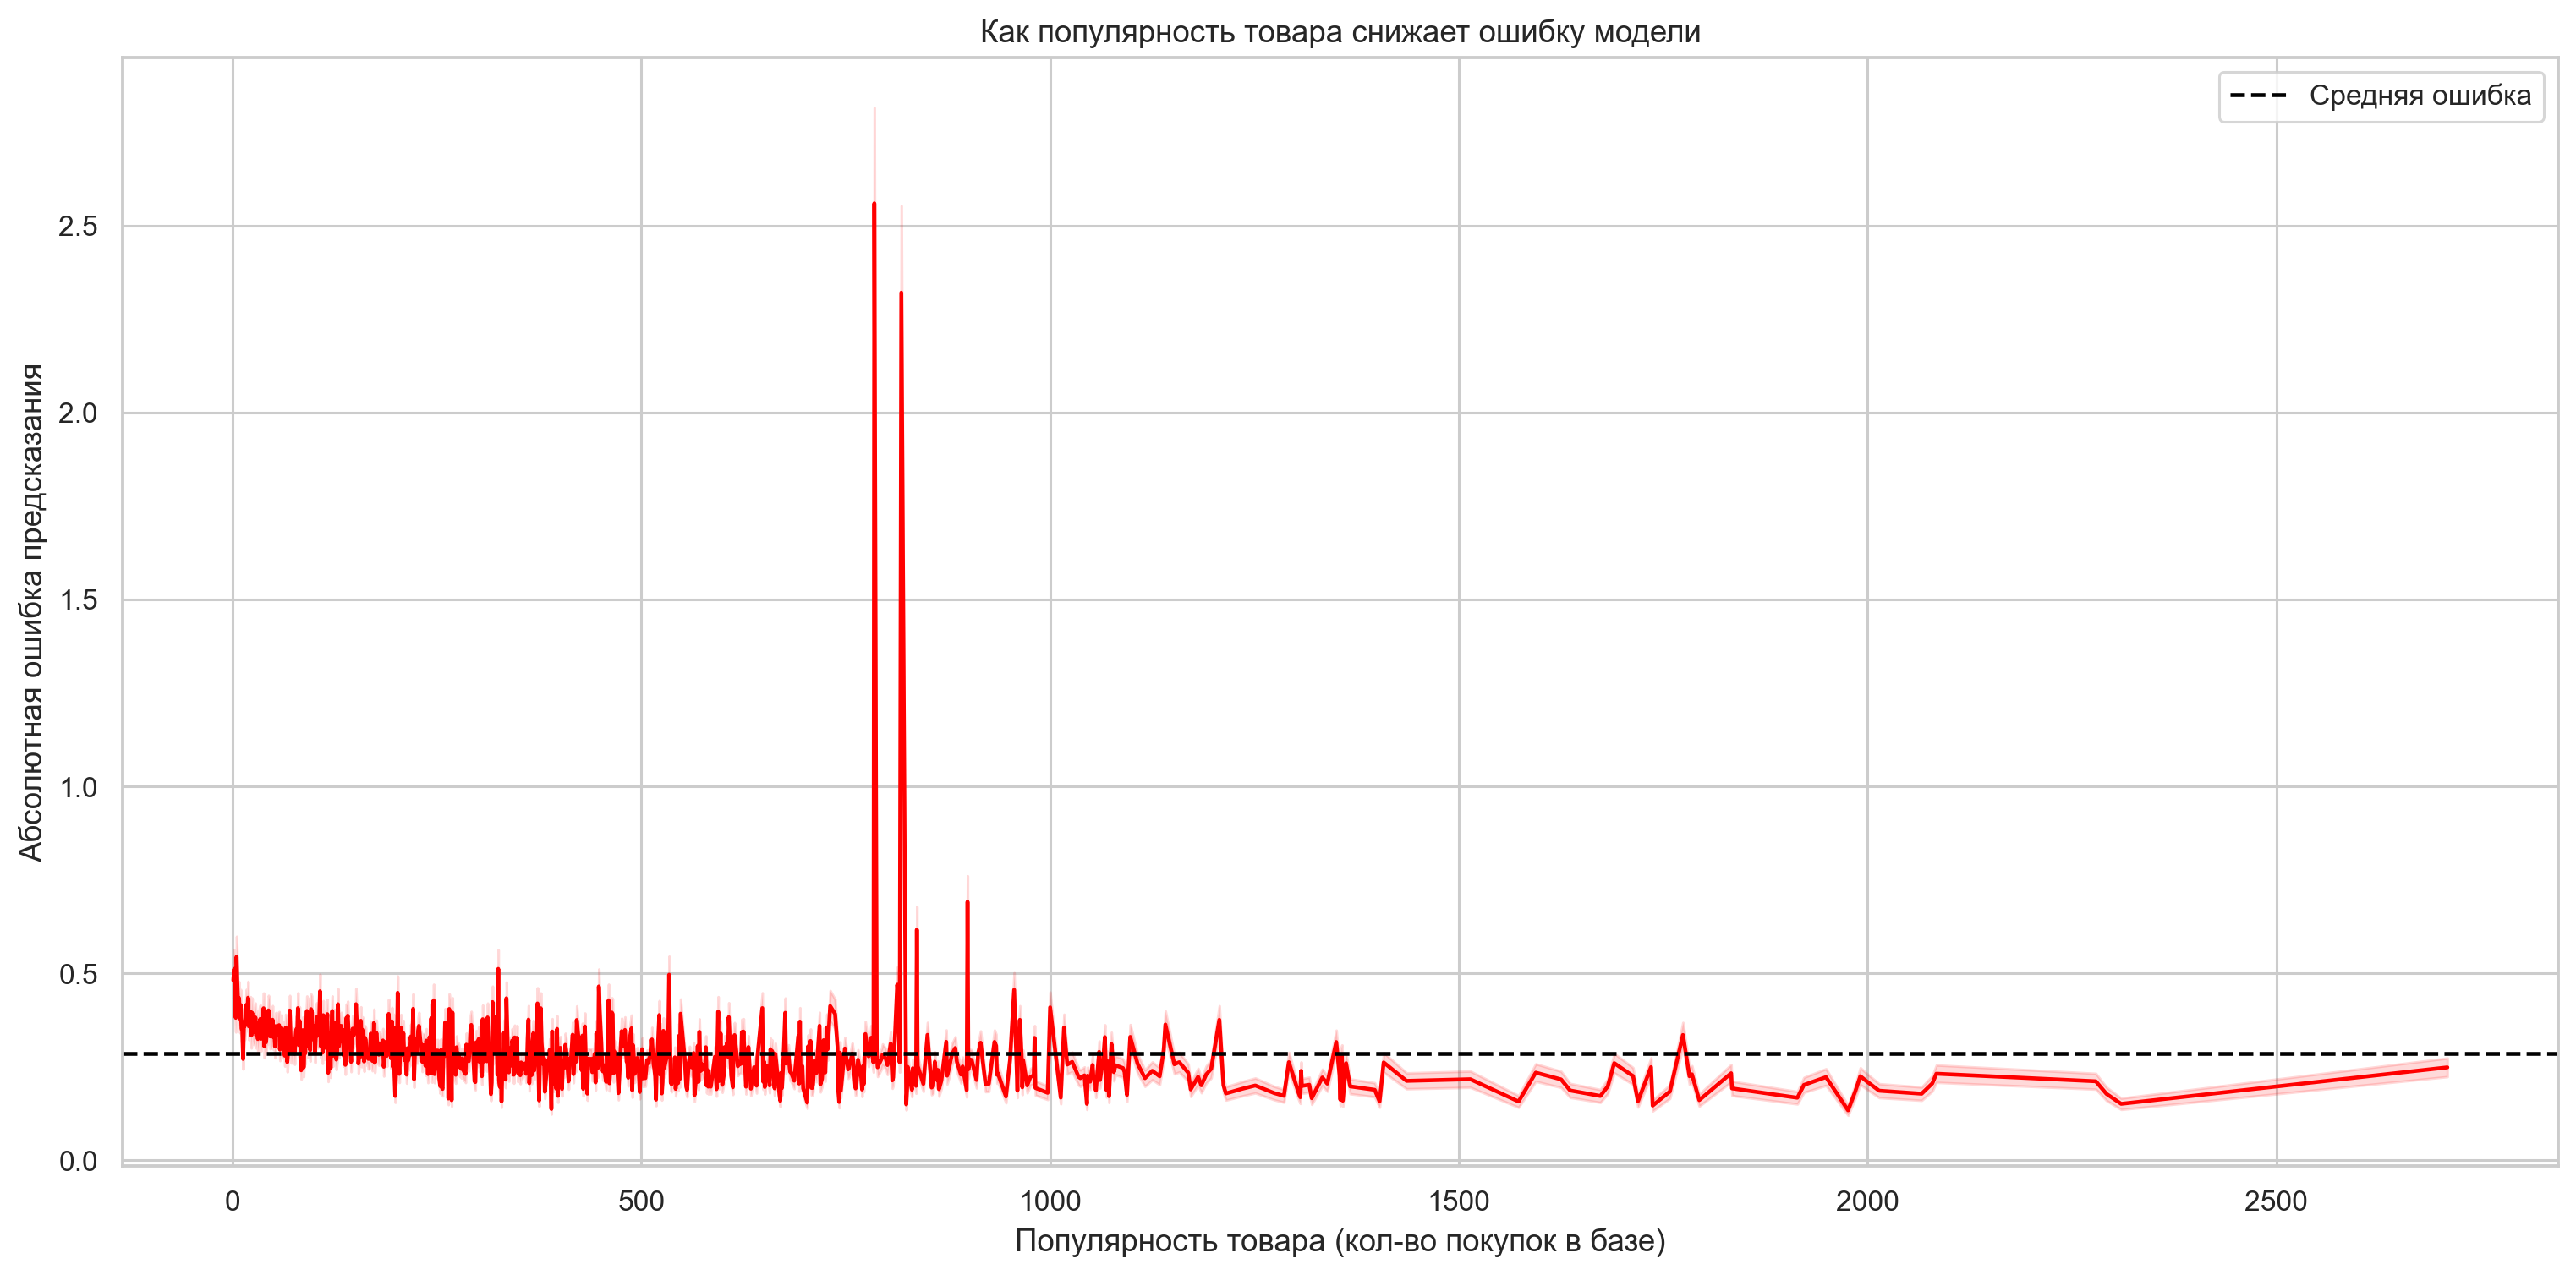

In [12]:
for image_name in [
    'rmse_improvement_comparison.png',
    'feature_importance_comparison.png',
    'final_ensemble_performance.png',
    'error_vs_popularity.png',
]:
    display(Markdown(f'### {image_name}'))
    display(Image(filename=str(dirs['figures'] / image_name)))


## 10. Финальное предсказание на тестовой выборке

Внизу формируется исследовательский файл сабмишена. Дополнительно сохраняется расширенная версия с `Comb`, чтобы было удобнее проверять соответствие строк тестовой выборке.

In [13]:
submission = pd.read_csv(results['submission_paths']['submission'])
submission_full = pd.read_csv(results['submission_paths']['submission_full'])
display(submission.head(10))
display(submission_full.head(10))
results['submission_paths']


,User_ID,Product_ID,Purchase
0,1000004,P00128942,17156
1,1000009,P00113442,11942
2,1000010,P00288442,6588
3,1000010,P00145342,2349
4,1000011,P00053842,2461
5,1000013,P00350442,11725
6,1000013,P00155442,12140
7,1000013,P0094542,11172
8,1000015,P00161842,13507
9,1000022,P00067942,5393


,Comb,User_ID,Product_ID,Purchase
0,1000004P00128942,1000004,P00128942,17156
1,1000009P00113442,1000009,P00113442,11942
2,1000010P00288442,1000010,P00288442,6588
3,1000010P00145342,1000010,P00145342,2349
4,1000011P00053842,1000011,P00053842,2461
5,1000013P00350442,1000013,P00350442,11725
6,1000013P00155442,1000013,P00155442,12140
7,1000013P0094542,1000013,P0094542,11172
8,1000015P00161842,1000015,P00161842,13507
9,1000022P00067942,1000022,P00067942,5393


{'submission': '<LOCAL_PATH>',
 'submission_full': '<LOCAL_PATH>'}

## 11. Вывод

Финальная версия решения переводит разрозненные экспериментальные наработки в воспроизводимый аналитический pipeline. Основная ценность новой структуры в том, что теперь можно отдельно обсуждать:
- качество данных и гипотез;
- вклад каждого семейства признаков;
- разницу между baseline и финальной моделью;
- устойчивость и интерпретируемость финального ансамбля;
- готовый файл предсказаний без ручных исправлений в конце ноутбука.